In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
titanic_df = pd.read_csv('./train.csv')
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].mean()) # 결측치를 age의 평균값으로 채움
titanic_df['Cabin'] = titanic_df['Cabin'].fillna('N') # 결측치를 n으로 채움
titanic_df['Embarked'] = titanic_df['Embarked'].fillna('N') # 결측치를 n으로 채움

titanic_df.isnull().sum() # 결측치 확인

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [5]:
titanic_df['Sex'].value_counts()

male      577
female    314
Name: Sex, dtype: int64

In [6]:
titanic_df['Cabin'].value_counts()

N              687
C23 C25 C27      4
G6               4
B96 B98          4
C22 C26          3
              ... 
E34              1
C7               1
C54              1
E36              1
C148             1
Name: Cabin, Length: 148, dtype: int64

In [7]:
titanic_df['Embarked'].value_counts()

S    644
C    168
Q     77
N      2
Name: Embarked, dtype: int64

In [8]:
titanic_df['Cabin'] = titanic_df['Cabin'].str[:1]

titanic_df['Cabin'].head()

0    N
1    C
2    N
3    C
4    N
Name: Cabin, dtype: object

In [9]:
# 성별 x 생존여부 교차 집계

titanic_df.groupby(['Sex', 'Survived'])['Survived'].count()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

<Axes: xlabel='Pclass', ylabel='Survived'>

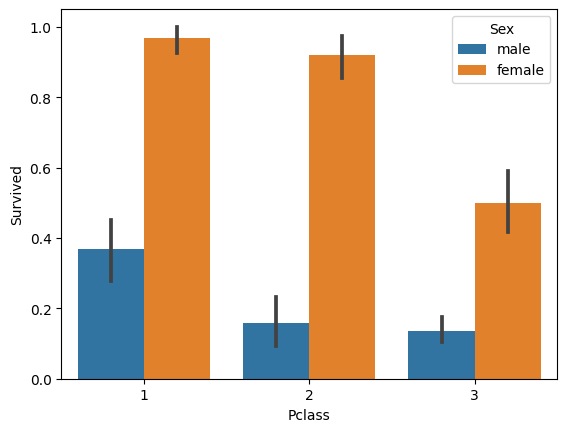

In [10]:
sns.barplot(x='Pclass', y= 'Survived', hue='Sex', data=titanic_df)

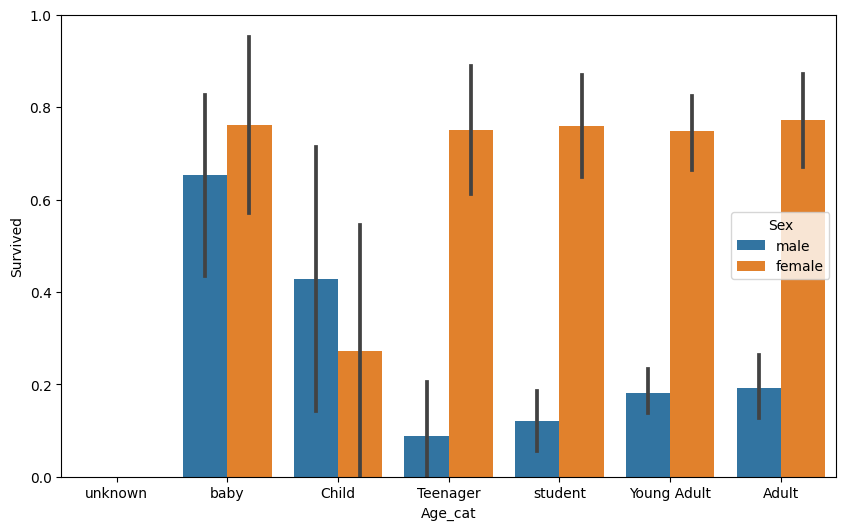

In [11]:
def get_category(age) :
    cat = ""
    if age <= -1 : cat = 'unknown'
    elif age <= 5 : cat = 'baby'
    elif age <= 12 : cat = 'Child'
    elif age <= 18 : cat = 'Teenager'
    elif age <= 25 : cat = 'student'
    elif age <= 35 : cat = 'Young Adult'
    elif age <= 60 : cat = 'Adult'

    return cat

# 그래프 x축에 표시할 범주 순서를 지정
group_name = ['unknown', 'baby', 'Child', 'Teenager', 'student', 'Young Adult', 'Adult']
# get_category 적용하여 컬럼 생성
titanic_df['Age_cat'] = titanic_df['Age'].apply(lambda x : get_category(x))

plt.figure(figsize=(10, 6))
sns.barplot(x='Age_cat', y = 'Survived', hue='Sex', data=titanic_df, order = group_name)

titanic_df.drop('Age_cat', axis= 1, inplace = True)

In [12]:
from sklearn import preprocessing

def encode_features(df) :
    features = ['Cabin', 'Sex', 'Embarked']  # 인코딩할 범주형 목록
    for feature in features:
        le = preprocessing.LabelEncoder()  
        le = le.fit(df[feature])
        df[feature]= le.transform(df[feature])
    return df

titanic_df = encode_features(titanic_df)
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


In [13]:
titanic_df['Cabin'].value_counts()

7    687
2     59
1     47
3     33
4     32
0     15
5     13
6      4
8      1
Name: Cabin, dtype: int64

In [14]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


In [15]:
titanic_df.drop(['PassengerId', 'Name', 'Ticket'], axis= 1, inplace=True) # passenger, name, ticket 제거
titanic_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,1,22.0,1,0,7.2500,7,3
1,1,1,0,38.0,1,0,71.2833,2,0
2,1,3,0,26.0,0,0,7.9250,7,3
3,1,1,0,35.0,1,0,53.1000,2,3
4,0,3,1,35.0,0,0,8.0500,7,3


In [16]:
titanic_df['Fare'].isna().sum() # 결측치 확인

0

In [17]:
y_titanic_df = titanic_df['Survived']
X_titanic_df = titanic_df.drop('Survived', axis = 1)

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X_titanic_df, y_titanic_df, test_size=0.2, random_state= 11)

In [19]:
from sklearn.tree import DecisionTreeClassifier # 결정트리 분류기
from sklearn.ensemble import RandomForestClassifier # 랜덤포레스트 분류기
from sklearn.linear_model import LogisticRegression # 로지스틱 분류기
from sklearn.metrics import accuracy_score # 정확도 계산 함수


dt_clf = DecisionTreeClassifier(random_state=11)
rf_clf = RandomForestClassifier(random_state=11)
lr_clf = LogisticRegression(solver= 'liblinear')

# 결정트리 학습 및 예측
dt_clf.fit(X_train, Y_train)
dt_pred = dt_clf.predict(X_test)
print('결정트리정확도 :', accuracy_score(Y_test, dt_pred))

# 랜덤포레스트 학습 및 예측
rf_clf.fit(X_train, Y_train)
rf_pred = dt_clf.predict(X_test)
print('랜덤포레스트정확도 :', accuracy_score(Y_test, rf_pred))

# 로지스틱 학습 및 예측
lr_clf.fit(X_train, Y_train)
lr_pred = dt_clf.predict(X_test)
print('로지스틱회귀정확도 :', accuracy_score(Y_test, lr_pred))


결정트리정확도 : 0.7877094972067039
랜덤포레스트정확도 : 0.7877094972067039
로지스틱회귀정확도 : 0.7877094972067039


In [20]:
from sklearn.model_selection import KFold

def exec_kfold(clf, folds = 5):
    kfold = KFold(n_splits= folds)
    scores = []

    for iter_count, (train_index, test_index) in enumerate(kfold.split(X_titanic_df)):
        X_train, X_test = X_titanic_df.values[train_index], X_titanic_df.values[test_index]
        Y_train, Y_test = y_titanic_df.values[train_index], y_titanic_df.values[test_index]

        clf.fit(X_train, Y_train)
        predictions = clf.predict(X_test)
        accuracy = accuracy_score(Y_test, predictions)
        scores.append(accuracy)
        print('교차검증정확도 :', accuracy)
    mean_score = np.mean(scores) # 5번의 fold 정확도를 평균 냄
    print('평균 정확도 :', mean_score)

exec_kfold(dt_clf, 5)

교차검증정확도 : 0.7541899441340782
교차검증정확도 : 0.7808988764044944
교차검증정확도 : 0.7865168539325843
교차검증정확도 : 0.7696629213483146
교차검증정확도 : 0.8202247191011236
평균 정확도 : 0.782298662984119


In [21]:
exec_kfold(rf_clf, 5)

교차검증정확도 : 0.7932960893854749
교차검증정확도 : 0.8089887640449438
교차검증정확도 : 0.8370786516853933
교차검증정확도 : 0.7752808988764045
교차검증정확도 : 0.8595505617977528
평균 정확도 : 0.8148389931579938


In [22]:
exec_kfold(lr_clf, 5)

교차검증정확도 : 0.7932960893854749
교차검증정확도 : 0.7921348314606742
교차검증정확도 : 0.7752808988764045
교차검증정확도 : 0.7471910112359551
교차검증정확도 : 0.8426966292134831
평균 정확도 : 0.7901198920343984


In [23]:
from sklearn.model_selection import GridSearchCV

parameters = {'max_depth': [2,  3, 5, 10],
              'min_samples_split' : [2, 3, 5],
              'min_samples_leaf': [1, 5, 8]}

grid_dclf = GridSearchCV(dt_clf, param_grid=parameters,
                         scoring='accuracy', cv = 5)
grid_dclf.fit(X_train, Y_train)

print(grid_dclf.best_params_)
print(grid_dclf.best_score_)

best_dclf = grid_dclf.best_estimator_

dpredicitions = best_dclf.predict(X_test)
accuracy = accuracy_score(Y_test, dpredicitions)

print(accuracy)

{'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
0.7991825076332119
0.8715083798882681
